# Comparing FN-DMC results from several packages

We made a comparison of local basis sets with splines obtained from plane waves.
With splines we have a lower energy, because the plane waves with large cutoffs reach the CBS limit. 
However, the plane waves also imply some other possible error, that we investigated, for instance the Kleinman-Bylander (KB) projection.

We did some preliminary tests at the HF level, where we can compare the results from the DFT codes (PWscf for the plane-waves, and PySCF for the local basis sets).

We summarise here the main results obtained.

## At the HF level

The error due to KB is of the order of 0.1 mH (at most it is 0.2 mH) for a water molecule.

### PWSCF:

We performed PWscf calculations with increasing box size, in order to extrapolate the infinite box limit.

|vacuum [Ang] | E[Hartree] | E [Ry] |
|-------|:----------:|--------|
|5| -16.9457| -33.89130774 Ry|
|6| -16.9456| -33.89121358 Ry|
|7| -16.9456| -33.89116132 Ry|
|8| -16.9456| -33.89113008 Ry|

| Extrapolation | Energy [Hartree]   |
|---------------|:-------------------|
|  a+b/x        | -16.9454123926527  |
|  a+b/x**c     | -16.9455256292671  |


### QMCPACK

These are QMCPACK VMC calculations of the spline wave function (with different values of the mesh factor), where no Jastrow is used, and we use open boundary conditions.
The difference between this number and the extrapolated value from PWscf is due to the KB approximation in PWscf. 

```
runs/W/pw_VMC/vmcDLA(mf0.5) -16.945313 +/- 0.000041 3.144838 +/- 0.008112 0.1856
runs/W/pw_VMC/vmcDLAmf0.8   -16.945379 +/- 0.000041 3.081212 +/- 0.001959 0.1818
runs/W/pw_VMC/vmcDLAmf1.0   -16.945364 +/- 0.000044 3.076979 +/- 0.002666 0.1816
```

### PySCF

This is the convergence of the HF energy for increasing basis set size.

```
runs/W_ccecp-ccpvdz/SCF/scf.output:converged SCF energy = -16.9328784437541
runs/W_ccecp-ccpvtz/SCF/scf.output:converged SCF energy = -16.9435246665035
runs/W_ccecp-ccpvqz/SCF/scf.output:converged SCF energy = -16.9448965250943
runs/W_ccecp-ccpv5z/SCF/scf.output:converged SCF energy = -16.9452271890764
runs/W_ccecp-ccpv6z/SCF/scf.output:converged SCF energy = -16.9453580187172
runs/W_ccecp-augccpvdz/SCF/scf.output:converged SCF energy = -16.9403270111112
runs/W_ccecp-augccpvtz/SCF/scf.output:converged SCF energy = -16.9446290867156
runs/W_ccecp-augccpvqz/SCF/scf.output:converged SCF energy = -16.945274829488
runs/W_ccecp-augccpv5z/SCF/scf.output:converged SCF energy = -16.9453732259853
runs/W_ccecp-augccpv6z/SCF/scf.output:converged SCF energy = -16.945423505628
```

### Pyscf-QMCPACK & PWscf-QMCPACK on ccecp-ccpvtz
```
Pyscf           -16.9435246665035
py_VMC          -16.943510(49)     Var[E_L] = 3.0876(54)
---
PWscf extrap.   -16.9455256292671
pw_VMC mf=0.5   -16.945313(41)                3.1448(81) 
pw_VMC mf=0.8   -16.945379(41)                3.0812(19) 
pw_VMC mf=1.0   -16.945364(44)                3.0770(27) 
```
So, wave function from PWscf+splines is better than the w.f. from the ccecp-ccpvtz basis by ca. **2 mH**!

**TO DO: TEST CASINO, with single and double mesh in splines, and with single and double precision**

In [1]:
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import pandas as pd
from io import StringIO

In [2]:
colors = {
    'TurboRVB' : 'red',
    'TurboRVB_DMCv1' : 'tomato',
    'TurboRVB_DMCv2' : 'indianred',
    'CASINO_limdmc5'   : 'green',
    'CASINO_limdmc6t'   : 'lime',
    'QMCPACK'  : 'blue',
    'CHAMP_Holland' : 'blueviolet', # set here the final name for Claudia Filippi's version
    'CHAMP_Cornell_Paris' : 'magenta',    # set here the final name for Cyrus Umrigar's version
    'QMC=Chem' : 'cyan',
    'QMeCha'   : 'orange',
    'PyQMC'    : 'black',
    'Amolqc'   : 'brown',
    'QWalk'    : 'olive',
    'QWalk_noncov'    : 'deeppink',
    'CMQMC'    : 'darkgray',
}

codes = list( colors.keys() )


systems = [ 'm', 'w', 'mw', 'm---w' ]
methods = [ 'LA', 'TM', 'DLA', 'DLTM' ]

syst_names = dict(zip(systems,['methane','water','complex','far']))

colors_opt = {
    'TurboRVB_sandro'  : 'lightsalmon',
    'QMCPACK_complex'  : 'skyblue',
    'CASINO_limdmc4'   : 'gold',
    'CASINO_limdmc5_j+'    : 'mediumseagreen',
    'CASINO_limdmc5_cbycJbufF'    : 'darkgreen',
    'CASINO_limdmc5t'   : 'yellow',
    #'CASINO_pw1000'    : 'lime',
    #'CASINO_pw1000_andes' : 'mediumseagreen',
}
methods_opt = ['LA0', 'TM0']
codes_opt = list( colors_opt.keys() )
colors_all = { **colors, **colors_opt }

codes_all = codes + codes_opt

taumax = 0.3 # 0.091

In [3]:
# Test reading csv
d = pd.read_csv('../QMC=Chem/energy_w_DLA.csv',
                  names=['a','ene','err'], decimal='.',
                  header=None)
#d['tau'] = d.a**2
d.index = d.a
d.index.name = 'tau'
d

dd = pd.DataFrame([d.ene,d.err]).T
dd

,ene,err
tau,,
0.0800,-17.253658,0.000012
0.0400,-17.246899,0.000012
0.0200,-17.244965,0.000015
0.0100,-17.244956,0.000020
0.0050,-17.245364,0.000021
0.0025,-17.245744,0.000023


In [4]:
# Test reading csv
d = pd.read_csv('../QWalk/energy_w_LA.csv',
                  names=['a','ene','err'], decimal='.',
                  header=None)
#d['tau'] = d.a**2
d.index = d.a
d.index.name = 'tau'
d

dd = pd.DataFrame([d.ene,d.err]).T
dd

,ene,err
tau,,
0.0800,-17.245916,0.000056
0.0400,-17.242476,0.000046
0.0200,-17.241339,0.000044
0.0100,-17.241115,0.000030
0.0050,-17.241005,0.000050
0.0025,-17.241130,0.000055


In [5]:
# Set the x value for the plots 
# most codes: x <- tau
# Turborvb:   x <- alar^2
# QMC=Chem:   x <- 20*tau
# because in QMC=Chem (where there are single-electron moves)
# tau is too small for a comparison in the plots


def x_axis( df, code ):
    x = np.array( df.index )
    if code.startswith('TurboRVB') and not ('DMC' in code):
        xnew = x**2
    elif code.startswith('QMC=Chem'):
        xnew = x #* 20
    else:
        xnew = x
    return xnew

#for code in data:
#    print(code)
#    d = data[code]
#    for calc in d:
#        df = d[calc]
#        try:
#            if code.startswith('TurboRVB'):
#                df['x'] = df.index**2
#            elif code.startswith('QMC=Chem'):
#                df['x'] = df.index * 20
#            else:
#                df['x'] = df.index
#        except:
#            pass
 
#data['QMC=Chem']['mw_DLA']
#data['TurboRVB']['mw_DLA']
#print(x_axis(data['QMCPACK']['mw_DLA'], 'QMCPACK'))

In [6]:
# TurboRVB results obtained with
# psuudo: ccECP
# basis: cc_pVTZ
# J. basis: O:3s1p, C:3s1p, H:3s

data = {}
for code in codes+codes_opt:
    data[code] = {}

for code in codes+codes_opt:
    if code.startswith('TurboRVB') and not ('DMC' in code):
        names = ['a','ene','err']
    else:
        names = ['tau','ene','err']
    for method in methods+methods_opt:
        for syst in systems:
            key = f'{syst}_{method}'
            try: 
                data[code][key] = pd.read_csv(
                    f'../{code}/energy_{key}.csv',
                    names=names, decimal='.',
                    header=None, index_col=names[0] )
            except:
                data[code][key] = None
                #print(f'No data for {code}, {method}, {syst}')
                
#data["TurboRVB"]
#data["QMCPACK"]
#data["QMC=Chem"]
#data['Amolqc']

In [7]:
data['QMCPACK_complex']

{'m_LA':             ene       err
 tau                      
 0.080 -8.082191  0.000021
 0.040 -8.082090  0.000019
 0.020 -8.082381  0.000021
 0.010 -8.082725  0.000023
 0.005 -8.083062  0.000023,
 'w_LA':              ene       err
 tau                       
 0.080 -17.242121  0.000024
 0.040 -17.241178  0.000024
 0.020 -17.241161  0.000024
 0.010 -17.241395  0.000023
 0.005 -17.241677  0.000022,
 'mw_LA':              ene       err
 tau                       
 0.080 -25.326212  0.000034
 0.040 -25.324951  0.000033
 0.020 -25.324839  0.000035
 0.010 -25.325163  0.000033
 0.005 -25.325507  0.000035,
 'm---w_LA':              ene       err
 tau                       
 0.080 -25.325313  0.000042
 0.040 -25.323926  0.000032
 0.020 -25.323898  0.000034
 0.010 -25.324173  0.000034
 0.005 -25.324615  0.000032,
 'm_TM':              ene       err
 tau                       
 0.0800 -8.082669  0.000018
 0.0400 -8.081962  0.000022
 0.0200 -8.081541  0.000019
 0.0100 -8.081341  0.000019
 0.005

In [8]:
# Compute binding energies

# Hartree to meV
c = 27.211396641308*1000

for code in codes+codes_opt:
    datac = data[code]
    for method in methods:
        try:
            m = datac[f'm_{method}']
            w = datac[f'w_{method}']
            mw = datac[f'mw_{method}']
            Eb = c*(mw.ene-m.ene-w.ene)
            Eb_err = c*(mw.err**2+m.err**2+w.err**2)**0.5
            df_Eb = pd.DataFrame([Eb, Eb_err]).T
            #print(df_Eb)
            datac[f'Eb_{method}'] = df_Eb.dropna()
        except:
            pass

data["TurboRVB"]['Eb_DLA']
#data['QMCPACK_complex']['Eb_DLA']
#data['QMC=Chem']['Eb_DLA']

,ene,err
a,,
0.05,-29.375846,2.310645
0.10,-31.450442,2.274088
0.15,-35.337618,2.293703
0.20,-31.976085,2.352447
0.25,-33.166801,2.324137
0.30,-29.829759,2.264428


In [9]:
data['TurboRVB_DMCv1']['Eb_TM']

,ene,err
tau,,
0.0025,-27.187476,3.511467
0.0050,-19.481616,3.539305
0.0100,-29.137286,2.979413
0.0200,-23.233662,3.074042
0.0300,-12.610922,3.072544
0.0500,4.853466,3.979994


In [10]:
data

{'TurboRVB': {'m_LA': None,
  'w_LA': None,
  'mw_LA': None,
  'm---w_LA': None,
  'm_TM':            ene       err
  a                       
  0.05 -8.080926  0.000064
  0.10 -8.081144  0.000060
  0.15 -8.081231  0.000063
  0.20 -8.081511  0.000064
  0.25 -8.081657  0.000065
  0.30 -8.081877  0.000063,
  'w_TM':             ene       err
  a                        
  0.05 -17.239627  0.000051
  0.10 -17.239859  0.000050
  0.15 -17.239984  0.000052
  0.20 -17.240263  0.000050
  0.25 -17.240604  0.000050
  0.30 -17.241017  0.000052,
  'mw_TM':             ene       err
  a                        
  0.05 -25.321603  0.000037
  0.10 -25.321946  0.000037
  0.15 -25.322342  0.000039
  0.20 -25.322832  0.000038
  0.25 -25.323417  0.000037
  0.30 -25.324006  0.000040,
  'm---w_TM':             ene       err
  a                        
  0.05 -25.320553  0.000023
  0.10 -25.320855  0.000015
  0.15 -25.321266  0.000011
  0.20 -25.321773  0.000011
  0.25 -25.322310  0.000010
  0.30 -25.322932  

Exception for method LA code TurboRVB
Exception for method LA code TurboRVB_DMCv1
Exception for method LA code TurboRVB_DMCv2
Exception for method LA code QMCPACK
Exception for method LA code QMC=Chem
Exception for method LA code Amolqc
Exception for method TM code QMC=Chem
Exception for method TM code QMeCha
Exception for method TM code Amolqc
Exception for method DLA code TurboRVB_DMCv1
Exception for method DLA code TurboRVB_DMCv2
Exception for method DLA code CHAMP_Holland
Exception for method DLA code CHAMP_Cornell_Paris
Exception for method DLA code QWalk
Exception for method DLTM code TurboRVB_DMCv1
Exception for method DLTM code TurboRVB_DMCv2
Exception for method DLTM code QMCPACK
Exception for method DLTM code CHAMP_Holland
Exception for method DLTM code CHAMP_Cornell_Paris
Exception for method DLTM code QMC=Chem
Exception for method DLTM code QMeCha
Exception for method DLTM code PyQMC
Exception for method DLTM code Amolqc
Exception for method DLTM code QWalk


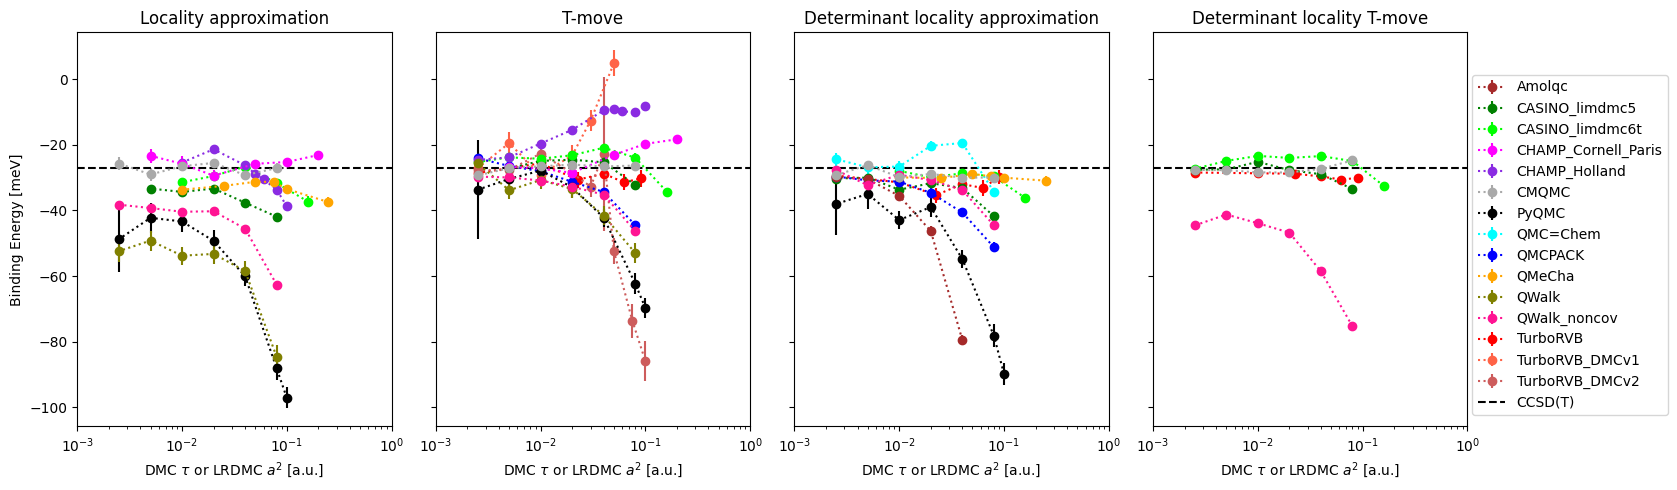

In [11]:
fig, ax = plt.subplots(1,4, figsize=(15,5), sharey=True, sharex=True )

ax[0].set_ylabel( 'Binding Energy [meV]' )
for i, method in enumerate(methods):
    #ax[i].set_xlim(0,taumax)
    ax[i].set_xlim(1e-3,1); ax[i].set_xscale('log')
    ax[i].set_xlabel( r'DMC $\tau$ or LRDMC $a^2$ [a.u.]' )
    for code in codes:
        try:
            datac1 = data[code][f'Eb_{method}']
            datac1['x'] = x_axis( datac1, code )
            datac = datac1[ datac1.x <= taumax ]
            x = datac.x
            #x = x_axis( datac, code )
            y = datac.ene
            y_err = datac.err
            ax[i].errorbar( x, y, y_err, fmt='o:', 
                           label=code, color=colors_all[code] )
        except:
            print(f'Exception for method {method} code {code}')
            pass
    ax[i].axhline(y=-27,color='black',ls='--',label='CCSD(T)')
    ax[i].label_outer()

ax[0].set_title('Locality approximation')
ax[1].set_title('T-move')
ax[2].set_title('Determinant locality approximation')
ax[3].set_title('Determinant locality T-move')

#ax[1].set_title('Water')
#ax[0].legend(loc=1)
#ax[1].legend()
#ax[2].legend()
#ax[3].legend()
#handles, labels = ax[2].get_legend_handles_labels()
#fig.legend(labels=labels, handles=handles, ncol=1, loc='center', bbox_to_anchor=( 1.05, 0.5))


leg = {}
for i in range(4): 
    handles, labels = ax[i].get_legend_handles_labels()
    for j in range(len(labels)):
        leg[labels[j]] = handles[j]
import collections
leg = collections.OrderedDict(sorted(leg.items()))
aus = leg['CCSD(T)']; del(leg['CCSD(T)']); leg['CCSD(T)']=aus
legend_outside = fig.legend(labels=list(leg.keys()), handles=list(leg.values()), ncol=1, loc='center', bbox_to_anchor=( 1.05, 0.5))


plt.tight_layout()
fig.savefig('Fig_Eb.png',bbox_extra_artists=(legend_outside,),bbox_inches='tight')

In [12]:
print(leg.keys())

odict_keys(['Amolqc', 'CASINO_limdmc5', 'CASINO_limdmc6t', 'CHAMP_Cornell_Paris', 'CHAMP_Holland', 'CMQMC', 'PyQMC', 'QMC=Chem', 'QMCPACK', 'QMeCha', 'QWalk', 'QWalk_noncov', 'TurboRVB', 'TurboRVB_DMCv1', 'TurboRVB_DMCv2', 'CCSD(T)'])


In [13]:
# Hartree to meV
c = 27.211396641308*1000

# compute the size consistency error (SCE)
for code in codes+codes_opt:
    datac = data[code]
    for method in methods:
        try:
            m = datac[f'm_{method}']
            w = datac[f'w_{method}']
            far = datac[f'm---w_{method}']
            Eb = c*(far.ene-m.ene-w.ene)
            Eb_err = c*(far.err**2+m.err**2+w.err**2)**0.5
            df_Eb = pd.DataFrame([Eb, Eb_err]).T
            #print(df_Eb)
            datac[f'SCE_{method}'] = df_Eb
        except:
            pass

#data['TurboRVB']['SCE_DLA']

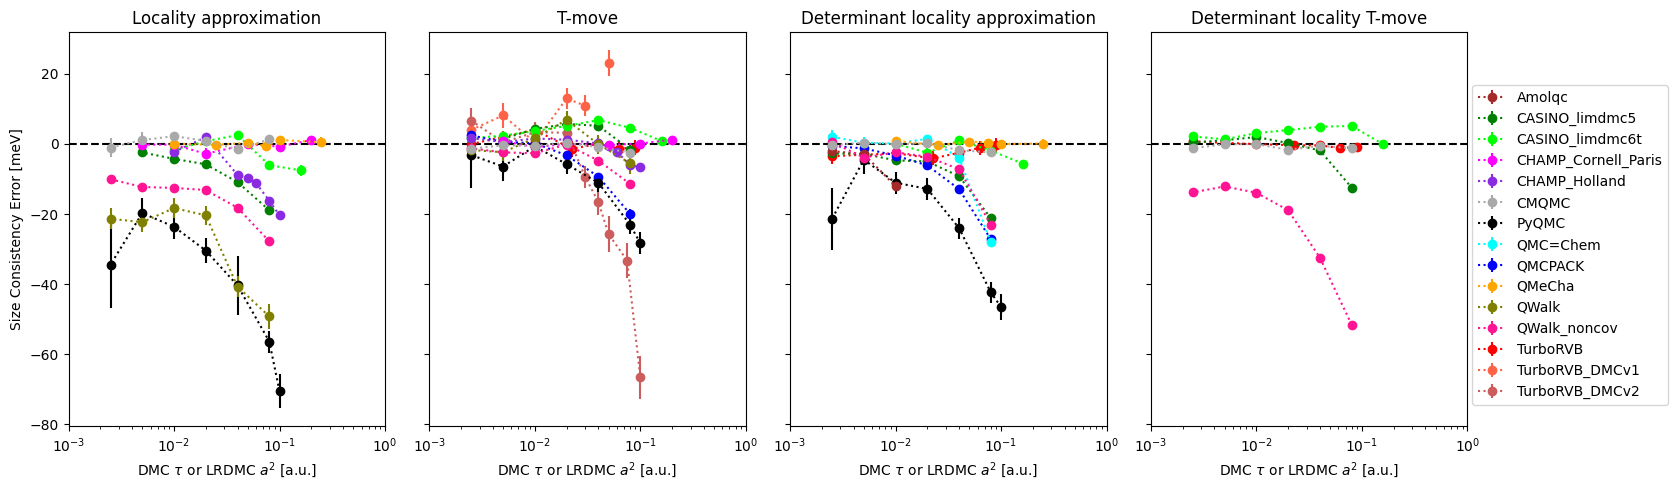

In [14]:
fig, ax = plt.subplots(1,4, figsize=(15,5), sharey=True, sharex=True )

ax[0].set_ylabel( 'Size Consistency Error [meV]' )
for i, method in enumerate(methods):
    #ax[i].set_xlim(0,taumax)
    ax[i].set_xlim(1e-3,1); ax[i].set_xscale('log')
    ax[i].set_xlabel( r'DMC $\tau$ or LRDMC $a^2$ [a.u.]' )
    for code in codes:
        try:
            datac1 = data[code][f'SCE_{method}']
            datac1['x'] = x_axis( datac1, code )
            datac = datac1[ datac1.x <= taumax ]
            x = datac.x
            y = datac.ene
            y_err = datac.err
            ax[i].errorbar( x, y, y_err, fmt='o:', 
                           label=code, color=colors_all[code] )
        except:
            pass
    ax[i].axhline(y=0.0,color='black',ls='--')

ax[0].set_title('Locality approximation')
ax[1].set_title('T-move')
ax[2].set_title('Determinant locality approximation')
ax[3].set_title('Determinant locality T-move')

#ax[1].set_title('Water')
#ax[0].legend(loc=1)
#ax[1].legend()
#ax[2].legend()
#ax[3].legend()


leg = {}
for i in range(4): 
    handles, labels = ax[i].get_legend_handles_labels()
    for j in range(len(labels)):
        leg[labels[j]] = handles[j]
import collections
leg = collections.OrderedDict(sorted(leg.items()))
#aus = leg['CCSD(T)']; del(leg['CCSD(T)']); leg['CCSD(T)']=aus
legend_outside = fig.legend(labels=list(leg.keys()), handles=list(leg.values()), ncol=1, loc='center', bbox_to_anchor=( 1.05, 0.5))


plt.tight_layout()
fig.savefig('Fig_SCE.png',bbox_extra_artists=(legend_outside,),bbox_inches='tight')

In [15]:
# Hartree to meV
c = 27.211396641308*1000

# compute the binding enegy in a size consistency way
# Ebsc = E[mw] - E[m---w]
for code in codes+codes_opt:
    datac = data[code]
    for method in methods:
        try:
            close = datac[f'mw_{method}']
            far = datac[f'm---w_{method}']
            Eb = c*(close.ene-far.ene)
            Eb_err = c*(close.err**2+far.err**2)**0.5
            df_Eb = pd.DataFrame([Eb, Eb_err]).T
            #print(df_Eb)
            datac[f'Ebsc_{method}'] = df_Eb
        except:
            pass

#data['TurboRVB']['Ebsc_DLA']
data['QMC=Chem']['Ebsc_DLA']

,ene,err
tau,,
0.0800,-6.207954,1.284879
0.0400,-15.584544,1.222823
0.0200,-21.766198,1.626936
0.0100,-26.796679,2.105381
0.0050,-27.176177,2.241706
0.0025,-26.485788,2.355473


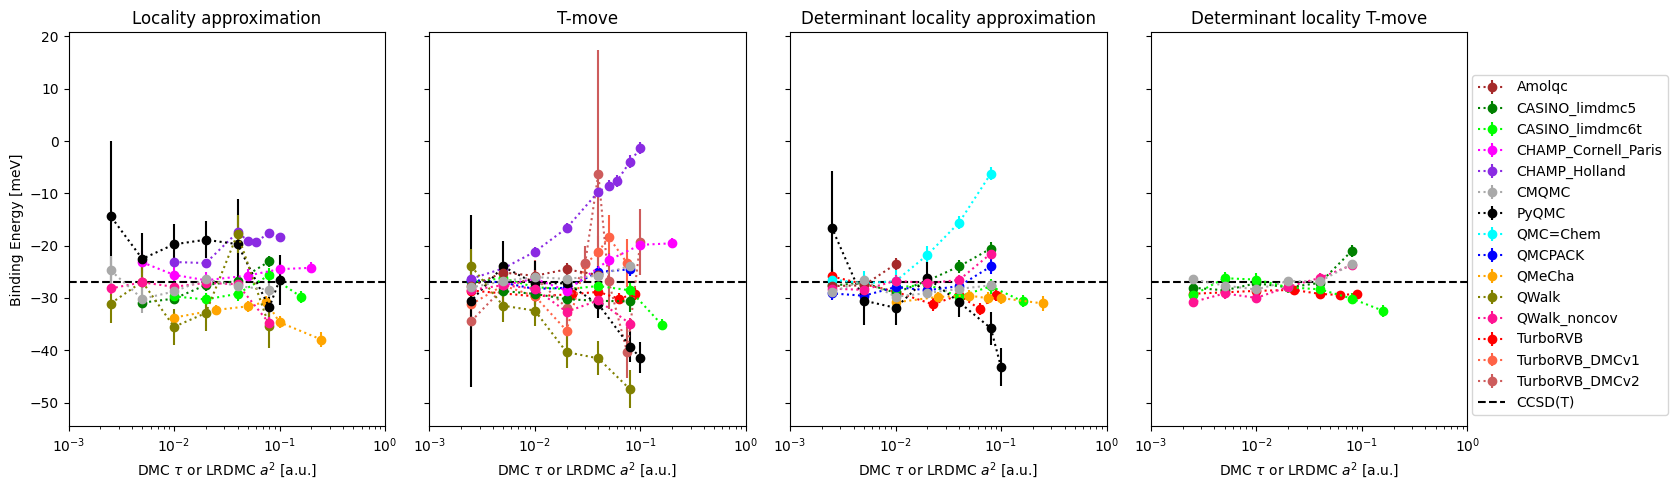

In [16]:
fig, ax = plt.subplots(1,4, figsize=(15,5), sharey=True, sharex=True )

ax[0].set_ylabel( 'Binding Energy [meV]' )
for i, method in enumerate(methods):
    #ax[i].set_xlim(0,taumax)
    ax[i].set_xlim(1e-3,1); ax[i].set_xscale('log')
    ax[i].set_xlabel( r'DMC $\tau$ or LRDMC $a^2$ [a.u.]' )
    for code in codes:
        try:
            datac1 = data[code][f'Ebsc_{method}']
            datac1['x'] = x_axis( datac1, code )
            datac = datac1[ datac1.x <= taumax ]
            x = datac.x
            y = datac.ene
            y_err = datac.err
            ax[i].errorbar( x, y, y_err, fmt='o:', 
                           label=code, color=colors_all[code] )
        except:
            pass
    ax[i].axhline(y=-27,color='black',ls='--',label='CCSD(T)')

ax[0].set_title('Locality approximation')
ax[1].set_title('T-move')
ax[2].set_title('Determinant locality approximation')
ax[3].set_title('Determinant locality T-move')

#ax[1].set_title('Water')
#ax[0].legend(loc=1)
#ax[1].legend()
#ax[2].legend()
#ax[2].legend()


leg = {}
for i in range(4): 
    handles, labels = ax[i].get_legend_handles_labels()
    for j in range(len(labels)):
        leg[labels[j]] = handles[j]
import collections
leg = collections.OrderedDict(sorted(leg.items()))
aus = leg['CCSD(T)']; del(leg['CCSD(T)']); leg['CCSD(T)']=aus
legend_outside = fig.legend(labels=list(leg.keys()), handles=list(leg.values()), ncol=1, loc='center', bbox_to_anchor=( 1.05, 0.5))


plt.tight_layout()
fig.savefig('Fig_Ebsc.png',bbox_extra_artists=(legend_outside,),bbox_inches='tight')

In [17]:
for x in data:
    print(x)

TurboRVB
TurboRVB_DMCv1
TurboRVB_DMCv2
CASINO_limdmc5
CASINO_limdmc6t
QMCPACK
CHAMP_Holland
CHAMP_Cornell_Paris
QMC=Chem
QMeCha
PyQMC
Amolqc
QWalk
QWalk_noncov
CMQMC
TurboRVB_sandro
QMCPACK_complex
CASINO_limdmc4
CASINO_limdmc5_j+
CASINO_limdmc5_cbycJbufF
CASINO_limdmc5t


In [18]:
data['CMQMC']

{'m_LA':              ene       err
 tau                       
 0.0800 -8.081720  0.000026
 0.0400 -8.081567  0.000020
 0.0200 -8.081959  0.000020
 0.0100 -8.082365  0.000020
 0.0050 -8.082703  0.000028
 0.0025 -8.082954  0.000045,
 'w_LA':               ene       err
 tau                        
 0.0800 -17.241503  0.000025
 0.0400 -17.240224  0.000037
 0.0200 -17.240307  0.000020
 0.0100 -17.240832  0.000020
 0.0050 -17.241306  0.000020
 0.0025 -17.241772  0.000020,
 'mw_LA':               ene       err
 tau                        
 0.0800 -25.324219  0.000044
 0.0400 -25.322866  0.000020
 0.0200 -25.323204  0.000020
 0.0100 -25.324172  0.000020
 0.0050 -25.325076  0.000067
 0.0025 -25.325672  0.000056,
 'm---w_LA':               ene       err
 tau                        
 0.0800 -25.323175  0.000020
 0.0400 -25.321847  0.000020
 0.0200 -25.322233  0.000020
 0.0100 -25.323115  0.000037
 0.0050 -25.323967  0.000075
 0.0025 -25.324764  0.000086,
 'm_TM':              ene      err
 tau

In [19]:
systems

['m', 'w', 'mw', 'm---w']

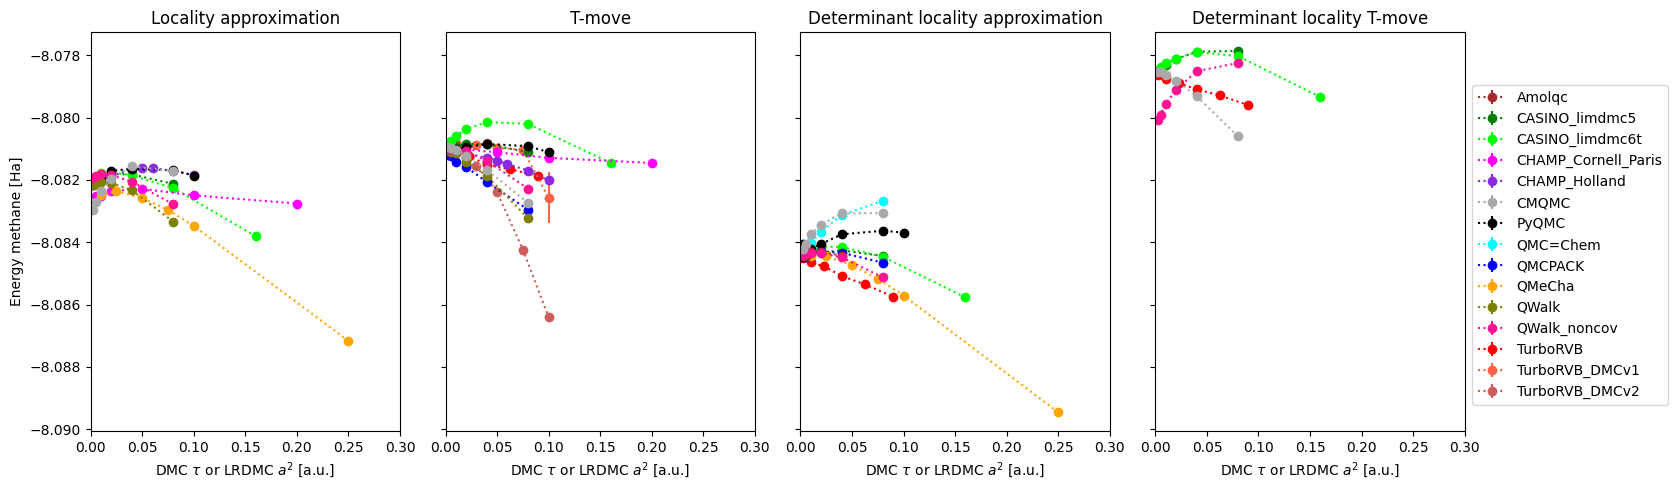

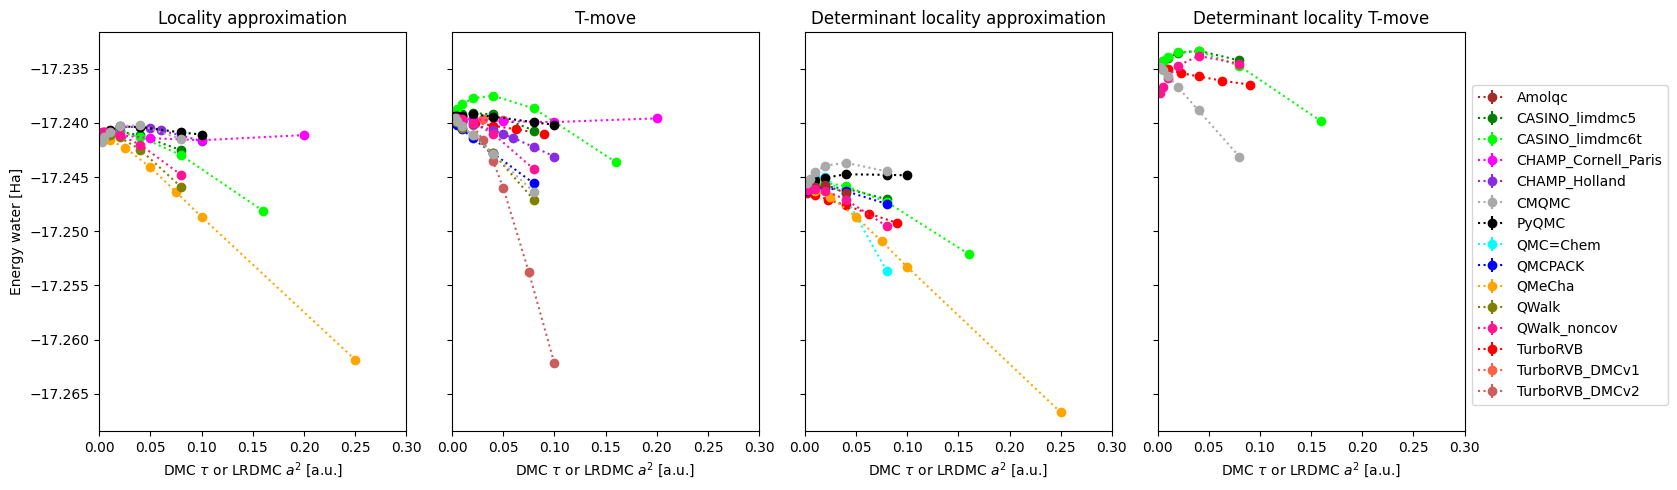

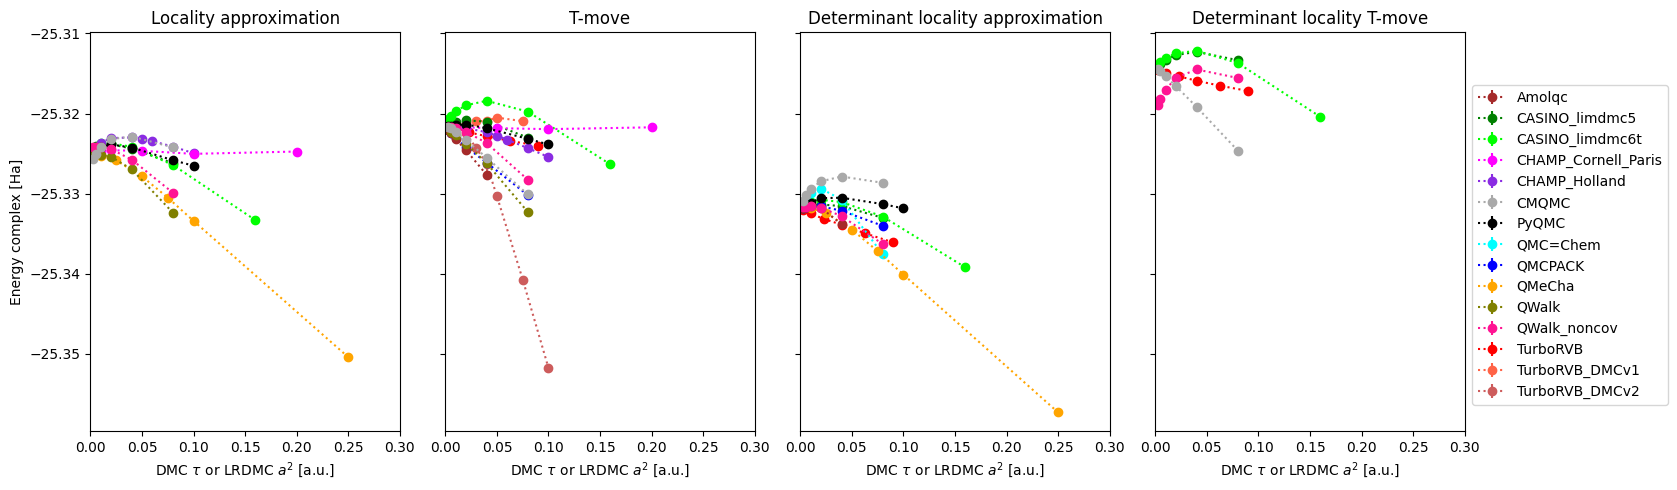

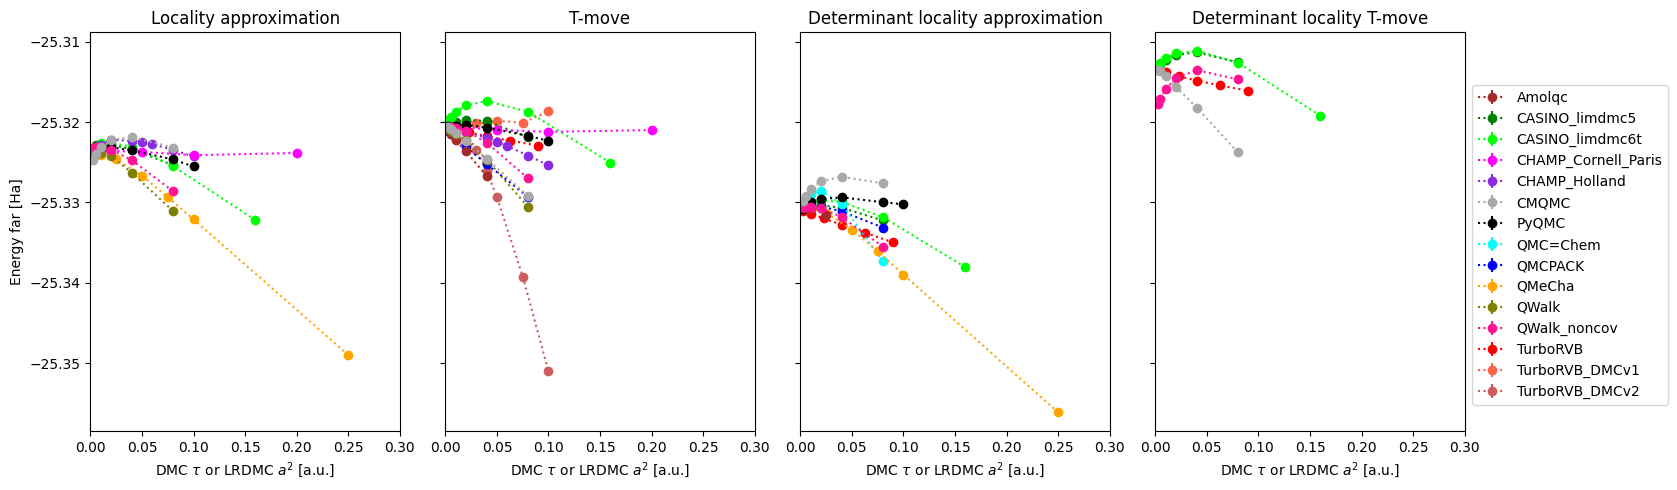

In [20]:
for syst in systems:
    fig, ax = plt.subplots(1,4, figsize=(15,5), sharey=True, sharex=True )

    ax[0].set_ylabel( f'Energy {syst_names[syst]} [Ha]' )
    for i, method in enumerate(methods):
        ax[i].set_xlim(0,taumax)
        #ax[i].set_xlim(1e-3,1); ax[i].set_xscale('log')
        ax[i].set_xlabel( r'DMC $\tau$ or LRDMC $a^2$ [a.u.]' )
        for code in codes:
            try:
                datac1 = data[code][f'{syst}_{method}']
                datac1['x'] = x_axis( datac1, code )
                datac = datac1[ datac1.x <= taumax ]
                x = datac.x
                y = datac.ene
                y_err = datac.err
                ax[i].errorbar( x, y, y_err, fmt='o:', 
                               label=code, color=colors_all[code] )
            except:
                pass

    ax[0].set_title('Locality approximation')
    ax[1].set_title('T-move')
    ax[2].set_title('Determinant locality approximation')
    ax[3].set_title('Determinant locality T-move')

    #ax[1].set_title('Water')
    #ax[0].legend(loc=1)
    #ax[1].legend()
    #ax[2].legend()
    #ax[3].legend()

    
    leg = {}
    for i in range(4): 
        handles, labels = ax[i].get_legend_handles_labels()
        for j in range(len(labels)):
            leg[labels[j]] = handles[j]
    import collections
    leg = collections.OrderedDict(sorted(leg.items()))
    #aus = leg['CCSD(T)']; del(leg['CCSD(T)']); leg['CCSD(T)']=aus
    legend_outside = fig.legend(labels=list(leg.keys()), handles=list(leg.values()), ncol=1, loc='center', bbox_to_anchor=( 1.05, 0.5))


    plt.tight_layout()
    fig.savefig(f'Fig_{syst}.png',bbox_extra_artists=(legend_outside,),bbox_inches='tight')

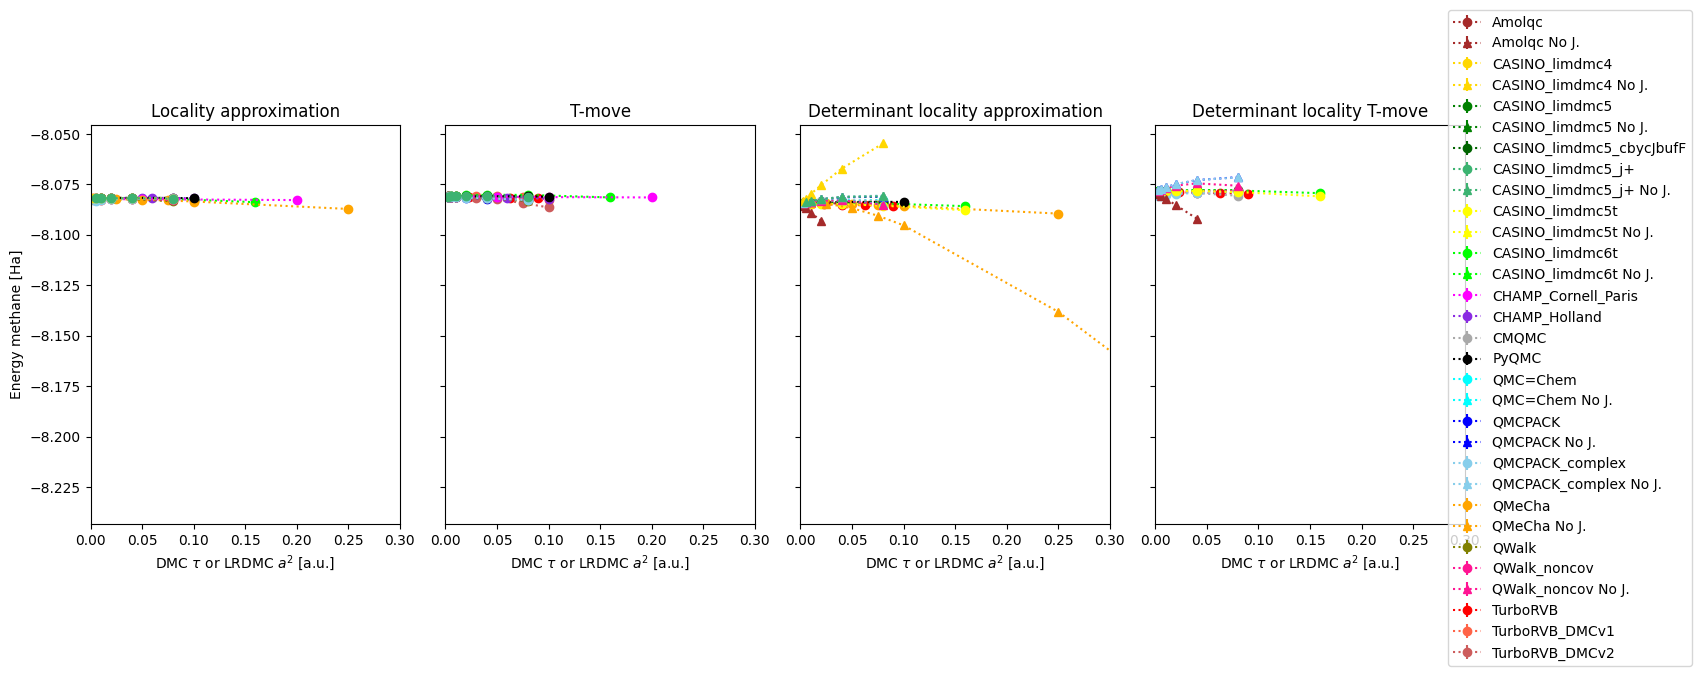

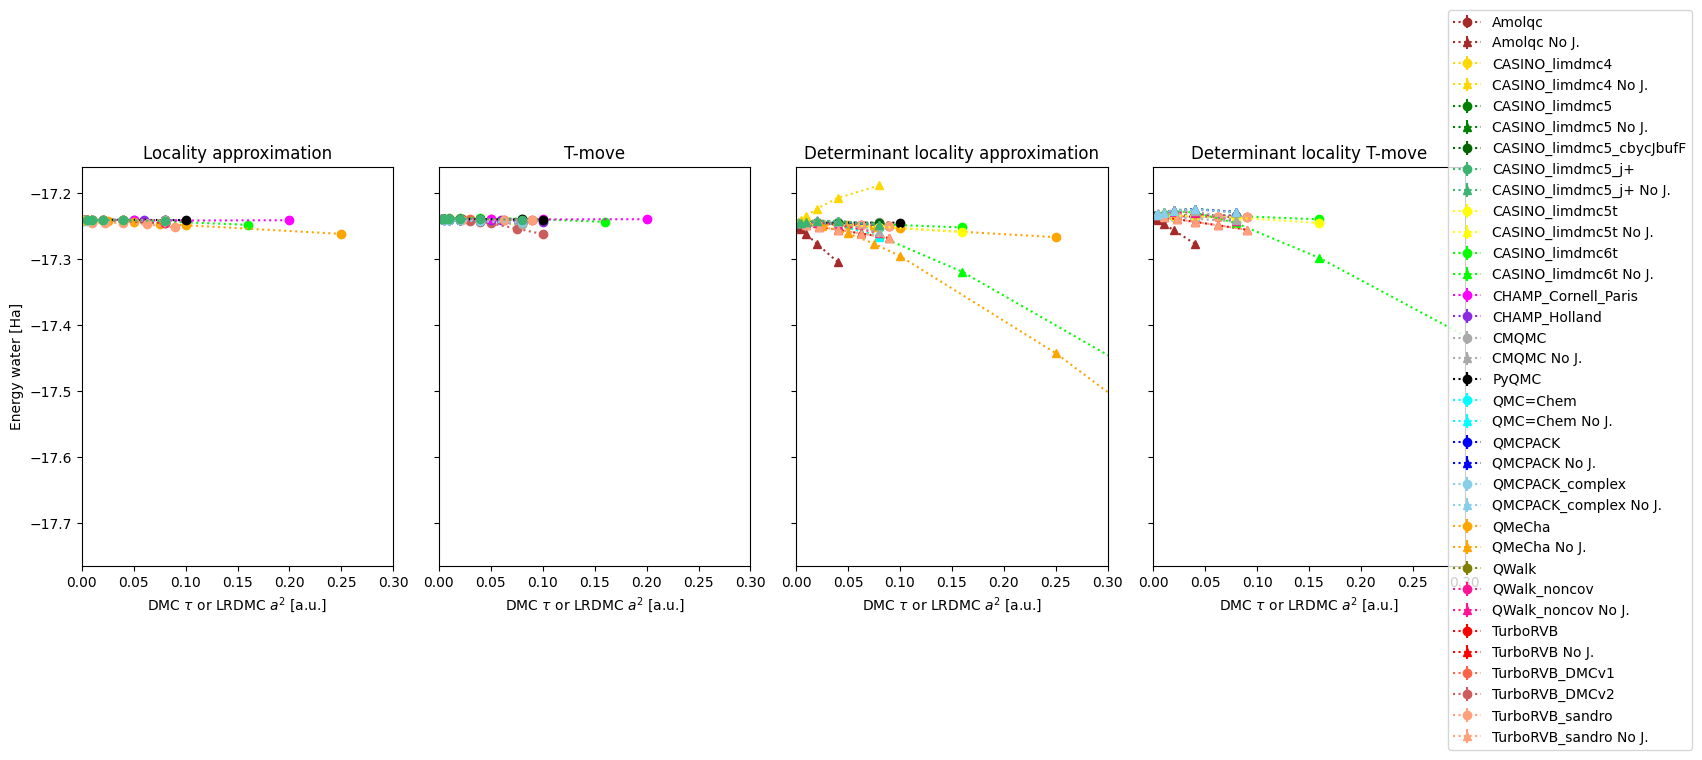

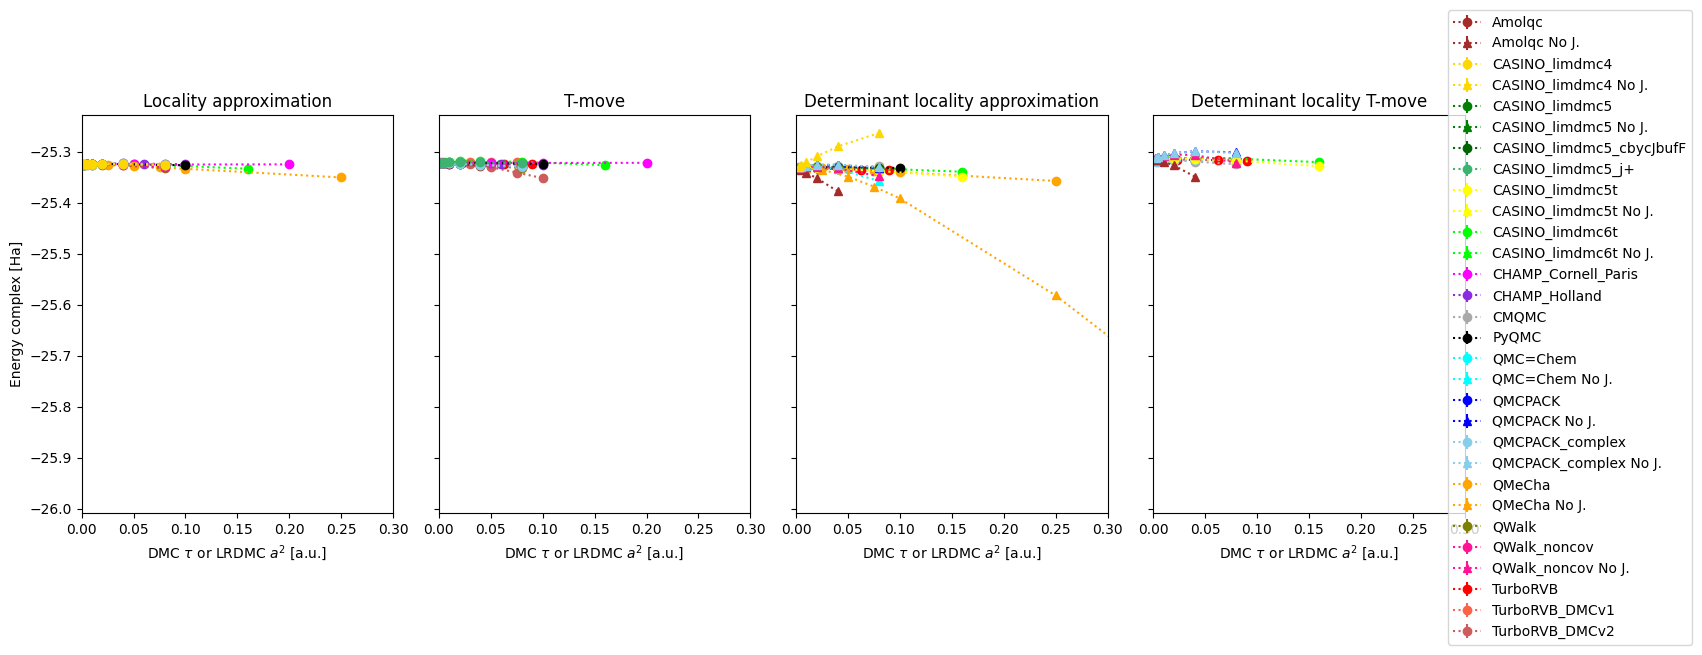

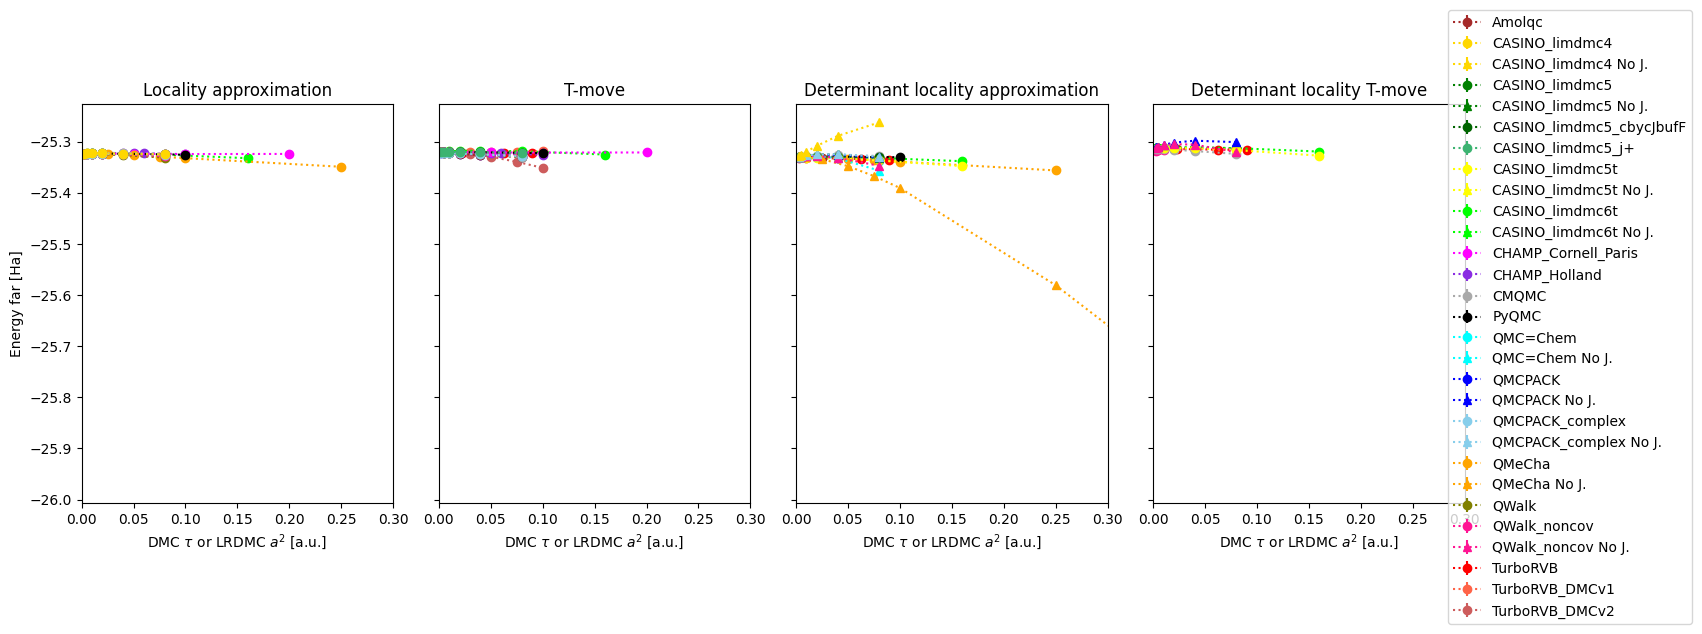

In [21]:
for syst in systems:
    fig, ax = plt.subplots(1,4, figsize=(15,5), sharey=True, sharex=True )

    ax[0].set_ylabel( f'Energy {syst_names[syst]} [Ha]' )
    for i, method in enumerate(methods):
        ax[i].set_xlim(0,taumax)
        ax[i].set_xlabel( r'DMC $\tau$ or LRDMC $a^2$ [a.u.]' )
        for code in codes+codes_opt:
            try:
                datac1 = data[code][f'{syst}_{method}']
                datac1['x'] = x_axis( datac1, code )
                datac = datac1[ datac1.x <= taumax ]
                x = datac.x
                #x = x_axis( datac, code )
                y = datac.ene
                y_err = datac.err
                ax[i].errorbar( x, y, y_err, fmt='o:', 
                               label=code, color=colors_all[code] )
            except:
                pass
    for j, method in enumerate(methods_opt):
        i = 2+j
        for code in codes+codes_opt:
            try:
                datac = data[code][f'{syst}_{method}']
                x = x_axis( datac, code )
                y = datac.ene
                y_err = datac.err
                ax[i].errorbar( x, y, y_err, fmt='^:', 
                               label=code+' No J.', 
                               color=colors_all[code],
                               markeredgecolor=colors_all[code],
                               markerfacecolor=None )
            except:
                pass

    ax[0].set_title('Locality approximation')
    ax[1].set_title('T-move')
    ax[2].set_title('Determinant locality approximation')
    ax[3].set_title('Determinant locality T-move')

    #ax[2].legend()

    
    leg = {}
    for i in range(4): 
        handles, labels = ax[i].get_legend_handles_labels()
        for j in range(len(labels)):
            leg[labels[j]] = handles[j]
    import collections
    leg = collections.OrderedDict(sorted(leg.items()))
    #aus = leg['CCSD(T)']; del(leg['CCSD(T)']); leg['CCSD(T)']=aus
    legend_outside = fig.legend(labels=list(leg.keys()), handles=list(leg.values()), ncol=1, loc='center', bbox_to_anchor=( 1.05, 0.5))


    plt.tight_layout()
    fig.savefig(f'Fig_{syst}_wNoJ.png',bbox_extra_artists=(legend_outside,),bbox_inches='tight')

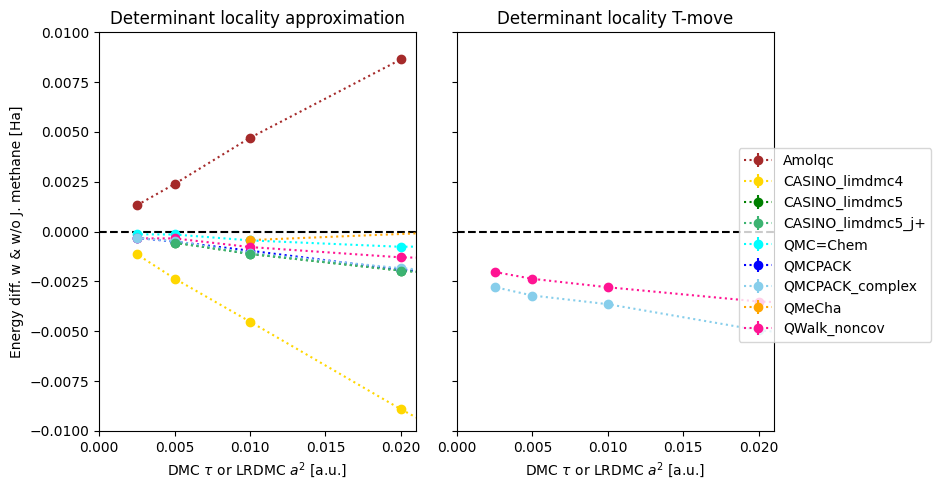

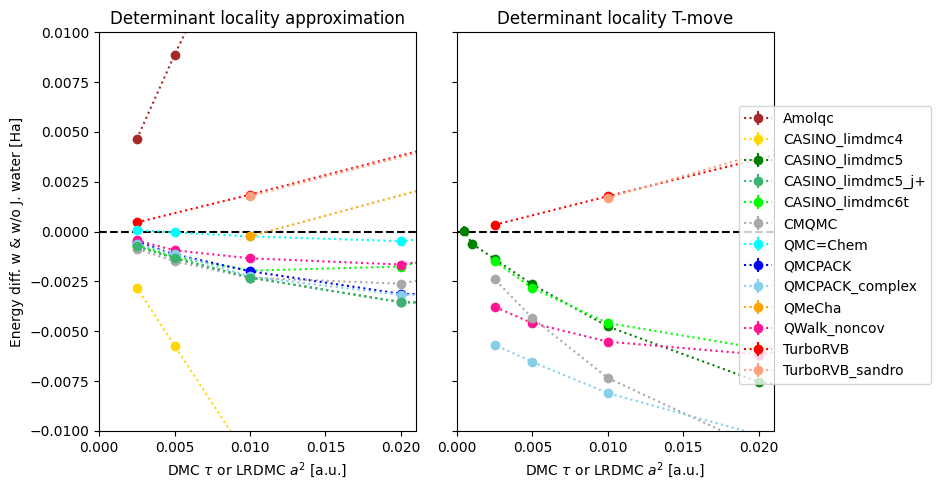

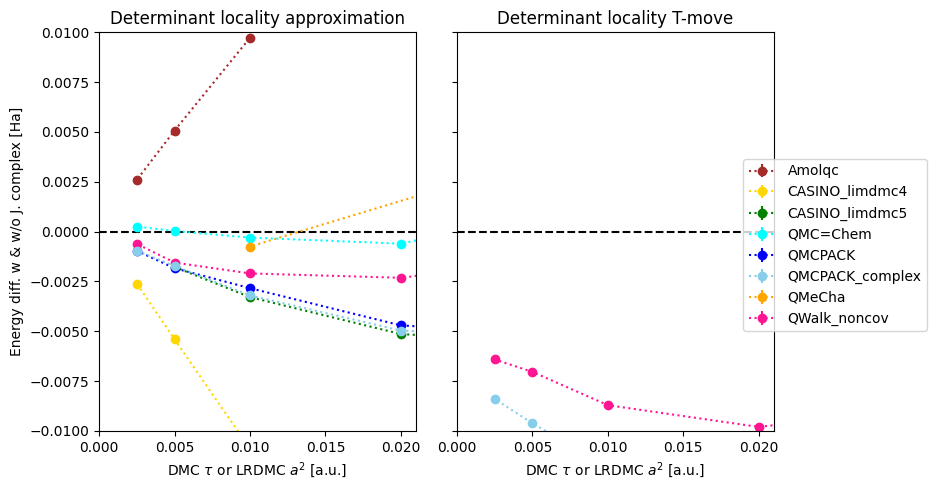

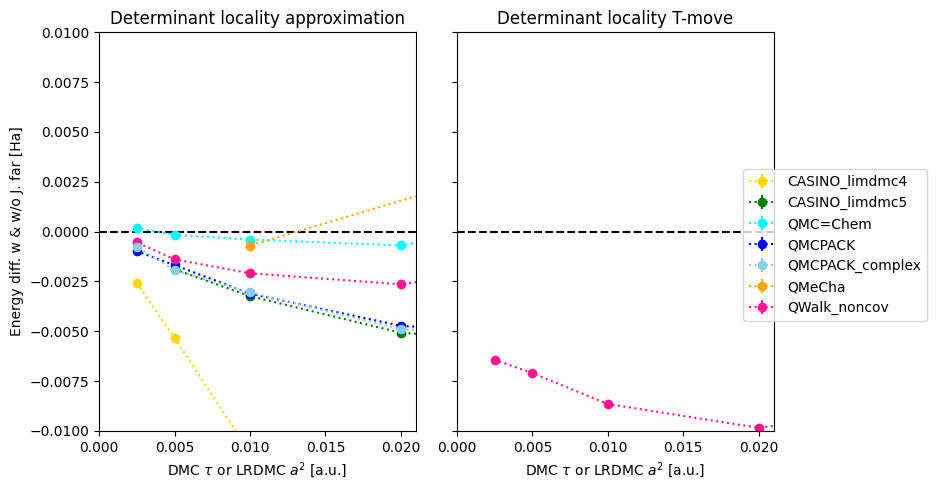

In [22]:
method2={}
method2['DLA']='LA0'
method2['DLTM']='TM0'

for syst in systems:
    fig, ax = plt.subplots(1,2, figsize=(8,5), sharey=True, sharex=True )

    ax[0].set_ylabel( f'Energy diff. w & w/o J. {syst_names[syst]} [Ha]' )
    for i, method in enumerate(['DLA','DLTM']):
        ax[i].axhline(y=0.0,color='black',ls='--',label='')
        ax[i].set_xlim(0,taumax)
        ax[i].set_xlabel( r'DMC $\tau$ or LRDMC $a^2$ [a.u.]' )
        for code in codes+codes_opt:
            try:
                datac1 = data[code][f'{syst}_{method}']
                datac0 = data[code][f'{syst}_{method2[method]}']
                datac = datac1 - datac0
                datac.err = (( datac1.err**2 + datac0.err**2 )**0.5)
                #print(code,method,'\n',datac0,datac1,datac)
                x = x_axis( datac, code )
                y = datac.ene
                y_err = datac.err
                ax[i].errorbar( x, y, y_err, fmt='o:', 
                               label=code, color=colors_all[code] )
            except:
                pass

    ax[0].set_title('Determinant locality approximation')
    ax[1].set_title('Determinant locality T-move')
    ax[0].set_xlim((0.,0.021))
    ax[0].set_ylim((-0.01,0.01))


    #ax[0].legend()

    
    leg = {}
    for i in range(2): 
        handles, labels = ax[i].get_legend_handles_labels()
        for j in range(len(labels)):
            leg[labels[j]] = handles[j]
    import collections
    leg = collections.OrderedDict(sorted(leg.items()))
    #aus = leg['CCSD(T)']; del(leg['CCSD(T)']); leg['CCSD(T)']=aus
    legend_outside = fig.legend(labels=list(leg.keys()), handles=list(leg.values()), ncol=1, loc='center', bbox_to_anchor=( 1.05, 0.5))


    fig.tight_layout()
    fig.savefig(f'Fig_{syst}_sanity_DL.png',bbox_extra_artists=(legend_outside,),bbox_inches='tight')

# Save all data in file

In [23]:
import pickle

with open('results_data.pkl','wb') as fp:
    pickle.dump(data, fp)
    print('Dictionary data with all results saved in results_data.pkl')

Dictionary data with all results saved in results_data.pkl
